# Prédire le prix d'un billet d'avion en Inde

**Projet IAS — Licence 3 · Youssef Mir**

Peut-on estimer le prix d'un vol intérieur indien à partir de ce que l'on sait au moment de le chercher : compagnie, itinéraire, date et horaires ? Ce notebook nettoie les 10 683 vols du jeu de données, explore ce qui fait varier le prix, puis compare cinq familles de modèles avec un protocole sans fuite d'information.

**Résultat.** Un gradient boosting appris sur le logarithme du prix se trompe en moyenne de **615 ₹ (≈ 7,80 €)**, soit **6,9 %** du prix. Il explique **94 %** de la variance des prix sur un jeu de test resté inutilisé pendant toute la mise au point.

**Plan**

1. Les données
2. Nettoyage
3. Ce qui fait le prix
4. Variables explicatives
5. Protocole d'évaluation
6. Comparaison des modèles
7. Réglage du gradient boosting
8. Évaluation finale sur le jeu de test
9. Interprétation
10. Conclusion et limites

## 0. Mise en place

Le code réutilisable (chargement, nettoyage, variables, modèles, graphiques) se trouve dans le package `src/flight_prices`. Le notebook l'appelle et commente les résultats. Les prix sont en roupies indiennes (₹) ; l'équivalent en euros utilise le taux de référence moyen de la BCE en 2019 (1 € = 78,84 ₹).

In [1]:
%matplotlib inline
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import display

from flight_prices import modeling, plotting
from flight_prices.config import INR_PER_EUR_2019, inr_to_eur
from flight_prices.data import clean, economy_only, load_raw
from flight_prices.features import build_features, count_conflicts, group_info
from flight_prices.labels import (
    DURATION_BINS,
    DURATION_LABELS,
    FEATURE_LABELS,
    INFO_LABELS,
    STOPS_LABELS,
    fr,
    fr_pct,
)

plotting.use_style()
pd.set_option("display.max_columns", 30)
print(f"Taux de conversion : 1 € = {fr(INR_PER_EUR_2019, 4)} ₹ (moyenne BCE 2019)")

Taux de conversion : 1 € = 78,8361 ₹ (moyenne BCE 2019)


## 1. Les données

> **Question.** Que contient le jeu de données, et quelle est sa qualité ?

Les données proviennent du concours *Flight Ticket Price Prediction* de MachineHack. Chaque ligne décrit un vol intérieur indien proposé à la vente, dont la date de voyage est comprise entre mars et juin 2019, avec son prix en roupies.

In [2]:
raw = load_raw()
print(f"{fr(raw.shape[0])} vols × {raw.shape[1]} colonnes")
raw.head()

10 683 vols × 11 colonnes


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [3]:
quality = pd.DataFrame(
    {
        "type": raw.dtypes.astype(str),
        "valeurs manquantes": raw.isna().sum(),
        "modalités distinctes": raw.nunique(),
        "exemple": raw.iloc[1],
    }
)
display(quality)
print(f"Doublons exacts : {raw.duplicated().sum()} lignes")

,type,valeurs manquantes,modalités distinctes,exemple
Airline,object,0,12,Air India
Date_of_Journey,object,0,44,1/05/2019
Source,object,0,5,Kolkata
Destination,object,0,6,Banglore
Route,object,1,128,CCU → IXR → BBI → BLR
Dep_Time,object,0,222,05:50
Arrival_Time,object,0,1343,13:15
Duration,object,0,368,7h 25m
Total_Stops,object,1,5,2 stops
Additional_Info,object,0,10,No info


Doublons exacts : 220 lignes


**Lecture.** Une seule ligne est incomplète (itinéraire et nombre d'escales manquants), mais **220 lignes sont des doublons exacts**. Les dates, horaires et durées sont stockés sous forme de texte (« 24/03/2019 », « 22:20 », « 2h 50m ») et doivent être convertis. Le libellé de compagnie mélange parfois compagnie et cabine (« Jet Airways Business », « Vistara Premium economy »).

Deux points demandent une décision avant de nettoyer.

**« Delhi » ou « New Delhi » ?** Les deux libellés de destination désignent le même aéroport (DEL dans la colonne `Route`). Le tableau ci-dessous montre ce qui les distingue.

In [4]:
from_bangalore = raw[raw["Source"] == "Banglore"]
month = pd.to_datetime(from_bangalore["Date_of_Journey"], format="%d/%m/%Y").dt.month
pd.crosstab(month.rename("mois du vol"), from_bangalore["Destination"])

Destination,Delhi,New Delhi
mois du vol,,
3,0,932
4,423,0
5,424,0
6,418,0


« New Delhi » n'apparaît qu'en mars, « Delhi » d'avril à juin. Le libellé ne décrit donc pas une autre destination : il trahit seulement la période de collecte. On fusionne les deux libellés et c'est la date du vol qui portera l'effet « mars ».

**Les billets en classe affaires.** Ils forment un produit à part :

In [5]:
business = raw["Airline"].str.contains("Business") | raw["Additional_Info"].eq("Business class")
raw.loc[business, ["Airline", "Date_of_Journey", "Route", "Duration", "Additional_Info", "Price"]]

,Airline,Date_of_Journey,Route,Duration,Additional_Info,Price
657,Jet Airways Business,01/03/2019,BLR → BOM → DEL,5h,No info,52229
2924,Jet Airways Business,01/03/2019,BLR → BOM → DEL,5h 40m,Business class,79512
3032,Jet Airways,01/03/2019,BLR → BDQ → DEL,6h 30m,Business class,28097
5372,Jet Airways Business,01/03/2019,BLR → BOM → DEL,6h 40m,Business class,62427
7351,Jet Airways Business,3/03/2019,DEL → ATQ → BOM → COK,8h 20m,No info,46490
9715,Jet Airways Business,6/03/2019,DEL → ATQ → BOM → COK,8h 20m,No info,52285
10364,Jet Airways Business,01/03/2019,BLR → MAA → DEL,4h 40m,Business class,57209


Sept billets, de 28 097 à 79 512 ₹, quand le prix médian d'un billet économique est d'environ 8 300 ₹. Sept exemples ne suffisent pas à apprendre ce tarif : on les décrit, mais on les exclut du modèle, dont le périmètre devient la classe économique (y compris premium économique).

## 2. Nettoyage

> **Question.** Quelles lignes garder, et sous quelle forme ?

In [6]:
tidy, report = clean(raw)
display(report.to_frame())
flights = economy_only(tidy)
print(f"Table nettoyée : {fr(len(tidy))} vols, dont {len(tidy) - len(flights)} en classe affaires")
print(f"Périmètre de modélisation : {fr(len(flights))} vols")
flights.head()

,étape,lignes retirées,lignes restantes
0,ligne incomplète (itinéraire et escales manqua...,1,10682
1,doublons exacts,220,10462
2,durée < 60 min (erreur de saisie),1,10461


Table nettoyée : 10 461 vols, dont 7 en classe affaires
Périmètre de modélisation : 10 454 vols


,airline,cabin,source,destination,route,journey_date,dep_time,duration_min,n_stops,additional_info,price
0,IndiGo,Economy,Bangalore,Delhi,BLR → DEL,2019-03-24,22:20,170,0,No info,3897
1,Air India,Economy,Kolkata,Bangalore,CCU → IXR → BBI → BLR,2019-05-01,05:50,445,2,No info,7662
2,Jet Airways,Economy,Delhi,Cochin,DEL → LKO → BOM → COK,2019-06-09,09:25,1140,2,No info,13882
3,IndiGo,Economy,Kolkata,Bangalore,CCU → NAG → BLR,2019-05-12,18:05,325,1,No info,6218
4,IndiGo,Economy,Bangalore,Delhi,BLR → NAG → DEL,2019-03-01,16:50,285,1,No info,13302


**Lecture.** Le nettoyage (fonction `clean`) :

- harmonise les libellés (« No Info » → « No info », « New Delhi » → « Delhi », « Banglore » → « Bangalore ») ;
- supprime la ligne incomplète et les **220 doublons exacts**. Un même vol présent deux fois pourrait sinon se retrouver à la fois dans l'entraînement et dans le test, ce qui gonflerait artificiellement les scores ;
- supprime une durée impossible (« 5m » pour un trajet à trois vols) ;
- sépare la compagnie et la cabine, puis convertit dates, heures, durées et escales en valeurs numériques. L'heure d'arrivée n'est pas conservée : elle se déduit de l'heure de départ et de la durée (c'est le cas pour 99,97 % des vols).

**Ce que l'on ne supprime pas : les tarifs élevés.** La version d'origine retirait les billets à plus de 300 €. Cela rendait le modèle incapable de prédire les vols chers et embellissait ses scores, puisqu'on retirait précisément les cas difficiles. Ici, seuls les sept billets en classe affaires sortent du périmètre, pour une raison métier. Il reste **10 454 vols**.

## 3. Ce qui fait le prix

> **Question.** Quels facteurs font varier le prix d'un billet ?

Prix médian : 8 266 ₹ (≈ 105 €)


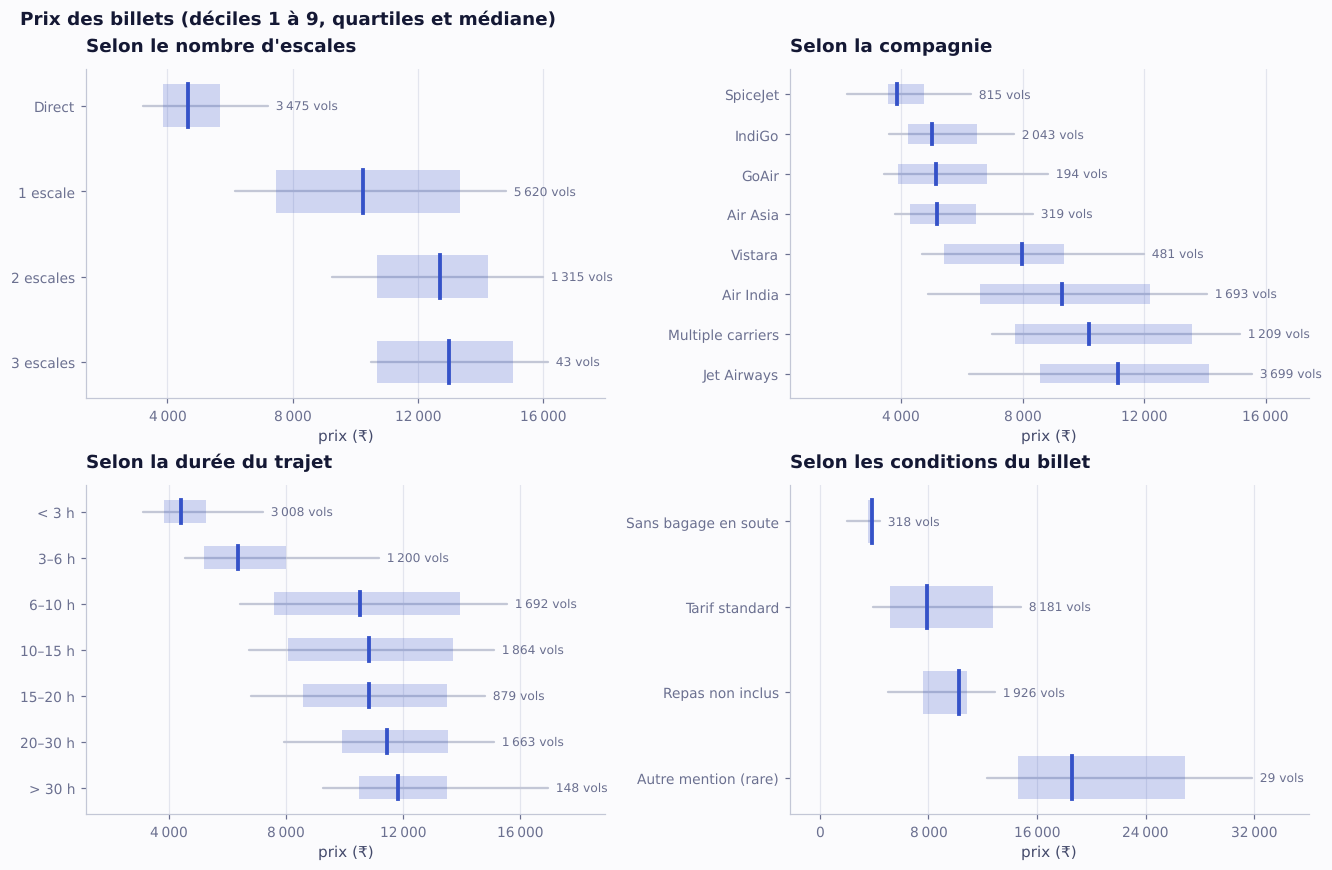

In [7]:
median = flights["price"].median()
print(f"Prix médian : {fr(median, unit='₹')} (≈ {fr(inr_to_eur(median), unit='€')})")

explore = flights.assign(
    escales=flights["n_stops"].map(STOPS_LABELS),
    durée=pd.cut(flights["duration_min"], DURATION_BINS, labels=DURATION_LABELS, right=False),
    conditions=flights["additional_info"].map(group_info).map(INFO_LABELS),
)
frequent_airlines = explore[explore.groupby("airline")["airline"].transform("size") >= 20]

fig, axes = plotting.new_figure(12, 7.8, nrows=2, ncols=2)
plotting.price_boxes(explore[explore["n_stops"] < 4], "escales", axes[0, 0],
                     order=["Direct", "1 escale", "2 escales", "3 escales"],
                     title="Selon le nombre d'escales")
plotting.price_boxes(frequent_airlines, "airline", axes[0, 1], title="Selon la compagnie")
plotting.price_boxes(explore, "durée", axes[1, 0], order=DURATION_LABELS,
                     title="Selon la durée du trajet")
plotting.price_boxes(explore, "conditions", axes[1, 1], title="Selon les conditions du billet")
fig.suptitle("Prix des billets (déciles 1 à 9, quartiles et médiane)", x=0.01, ha="left",
             fontweight="semibold", color=plotting.INK)
plotting.save(fig, "facteurs_prix")
plotting.plt.show()

**Lecture.**

- **Escales.** Un vol direct coûte en médiane 4 667 ₹, un vol avec une escale 10 262 ₹, soit 2,2 fois plus.
- **Compagnie.** Du low-cost SpiceJet (3 873 ₹) à Jet Airways (11 134 ₹), le prix médian varie du simple au triple.
- **Durée.** Le prix médian passe de 4 423 ₹ pour un trajet de moins de 3 h à 11 467 ₹ entre 20 et 30 h. Un trajet long n'est pas plus « confortable » : c'est un trajet avec escales, souvent vendu par une compagnie chère.
- **Conditions du billet.** Les billets sans bagage en soute (318 vols) sont les moins chers (3 841 ₹). La mention « repas non inclus » caractérise des tarifs Jet Airways : elle ne signale pas un rabais.

Ces facteurs sont liés entre eux : un vol direct est court, et Jet Airways opère surtout des trajets avec escale. Seul un modèle multivarié peut démêler leurs effets propres.

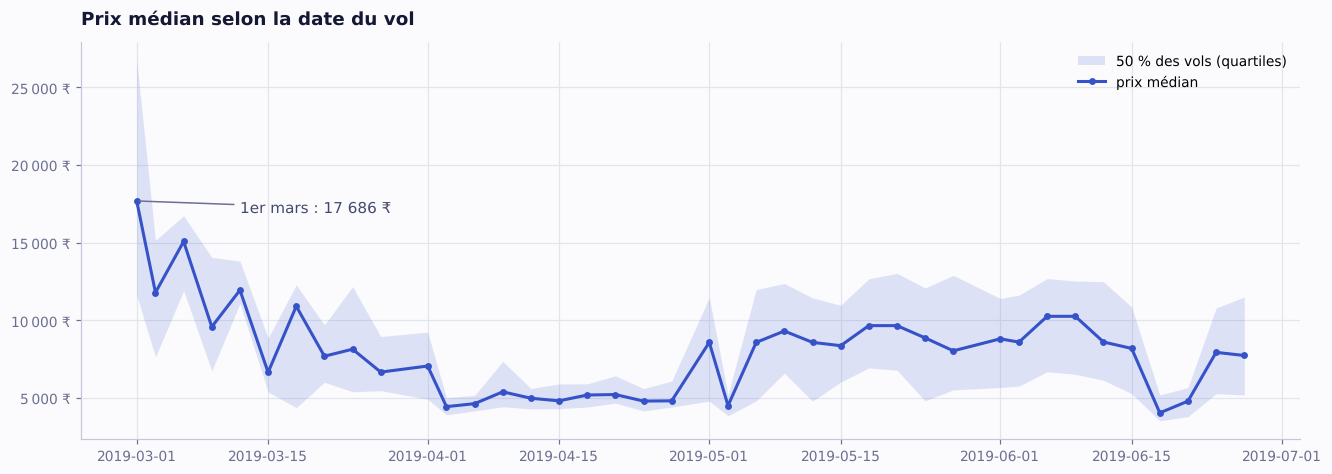

journey_date
2019-03-01    17686.0
2019-03-03    11791.0
2019-03-06    15077.0
Médiane des vols du 3 au 27 avril : 4 823 ₹


In [8]:
fig, ax = plotting.new_figure(12, 4.2)
plotting.median_price_by_date(flights, ax, title="Prix médian selon la date du vol")
ax.annotate("1er mars : 17 686 ₹", xy=(pd.Timestamp("2019-03-01"), 17686),
            xytext=(pd.Timestamp("2019-03-12"), 17000), color=plotting.INK_2,
            arrowprops={"arrowstyle": "-", "color": plotting.MUTED})
plotting.plt.show()

by_date = flights.groupby("journey_date")["price"].median()
print(by_date.head(3).to_string())
print(f"Médiane des vols du 3 au 27 avril : {fr(by_date['2019-04-03':'2019-04-27'].median(), unit='₹')}")

**Lecture.** La date du vol est le facteur le plus surprenant. Le 1er mars, le prix médian atteint **17 686 ₹**, près de quatre fois celui des vols de mi-avril (environ 4 800 ₹). Le jeu de données ne dit pas quand les billets ont été achetés. L'hypothèse la plus probable est que les prix ont été relevés début mars : les vols de début mars étaient alors achetés quelques jours avant le départ, au prix fort.

Un indice va dans ce sens. Le jeu contient des vols Jet Airways jusqu'à fin juin, alors que la compagnie a suspendu tous ses vols le 17 avril 2019 : les prix ont forcément été relevés avant cette date. Mai et juin, haute saison des vacances d'été, sont plus chers qu'avril. La date du vol sert donc ici de substitut au délai de réservation, une variable absente des données.

## 4. Variables explicatives

> **Question.** Comment traduire un vol en variables utilisables par un modèle ?

Chaque variable se calcule à partir de ce que connaît un voyageur au moment de chercher un vol (fonction `build_features`) :

| Variable | Construction |
|---|---|
| compagnie, cabine, ville de départ, ville d'arrivée | qualitatives, encodées en indicatrices (one-hot) dans le pipeline |
| conditions du billet | « standard », « repas non inclus », « sans bagage en soute » ; les mentions rares sont regroupées dans « autre » |
| nombre d'escales | 0 à 4 |
| escale à BOM, DEL, HYD… | une indicatrice par aéroport d'escale fréquent (≥ 100 vols) |
| durée | en minutes |
| heure de départ, heure d'arrivée | en minutes depuis minuit ; l'arrivée est calculée comme départ + durée |
| arrivée le lendemain | décalage en jours entre le départ et l'arrivée |
| date du vol | jour du mois, mois, jour de la semaine, jour de l'année |

In [9]:
X = build_features(flights)
y = flights["price"]
print(f"{X.shape[1]} variables pour {fr(X.shape[0])} vols")
X.head()

24 variables pour 10 454 vols


,airline,cabin,source,destination,additional_info,n_stops,duration_min,dep_minutes,arr_minutes,arr_day_offset,journey_day,journey_month,journey_weekday,journey_doy,via_BOM,via_DEL,via_HYD,via_MAA,via_AMD,via_JAI,via_BLR,via_BBI,via_IDR,via_NAG
0,IndiGo,Economy,Bangalore,Delhi,No info,0,170,1340,70,1,24,3,6,83,0,0,0,0,0,0,0,0,0,0
1,Air India,Economy,Kolkata,Bangalore,No info,2,445,350,795,0,1,5,2,121,0,0,0,0,0,0,0,1,0,0
2,Jet Airways,Economy,Delhi,Cochin,No info,2,1140,565,265,1,9,6,6,160,1,0,0,0,0,0,0,0,0,0
3,IndiGo,Economy,Kolkata,Bangalore,No info,1,325,1085,1410,0,12,5,6,132,0,0,0,0,0,0,0,0,0,1
4,IndiGo,Economy,Bangalore,Delhi,No info,1,285,1010,1295,0,1,3,4,60,0,0,0,0,0,0,0,0,0,1


In [10]:
print(f"{count_conflicts(X, y)} combinaisons de variables identiques ont plusieurs prix différents")

201 combinaisons de variables identiques ont plusieurs prix différents


**Lecture.** 24 variables décrivent chaque vol. Le dernier calcul fixe une limite à toute prédiction : **201 combinaisons de variables strictement identiques** (même vol, même date, même horaire) apparaissent avec des prix différents. Ces écarts dépendent d'informations absentes des données, comme le moment de l'achat ou le nombre de sièges restants, et aucun modèle ne peut les expliquer.

## 5. Protocole d'évaluation

> **Question.** Comment mesurer honnêtement la qualité d'un modèle ?

- **Un seul découpage** : 80 % des vols pour l'entraînement, 20 % pour le test. Le jeu de test est mis de côté et ne sert qu'une fois, à la toute fin.
- **Toute la mise au point** (choix du modèle, hyperparamètres, sélection des variables) se fait par **validation croisée à 5 plis sur l'entraînement**. La version d'origine choisissait ses réglages en regardant le jeu de test, ce qui rend ses scores optimistes.
- **Quatre métriques** : la MAE (erreur absolue moyenne, en ₹), la RMSE (racine de l'erreur quadratique moyenne, en ₹, qui pénalise les grosses erreurs), la MAPE (erreur relative moyenne) et le R² (part de la variance des prix expliquée). Elles remplacent le « pourcentage de bonne prédiction » d'origine (1 − RMSE / prix moyen), qui n'est pas une mesure standard.
- **Prix en logarithme.** Sauf pour la référence, les modèles apprennent log(prix) puis reviennent en roupies. Les écarts de prix sont multiplicatifs (une escale renchérit le billet d'un pourcentage plutôt que d'un montant fixe), et le logarithme réduit le poids des tarifs extrêmes.

In [11]:
x_train, x_test, y_train, y_test = modeling.split(X, y)
print(f"Entraînement : {fr(len(x_train))} vols — test : {fr(len(x_test))} vols")

Entraînement : 8 363 vols — test : 2 091 vols


## 6. Comparaison des modèles

> **Question.** Quelle famille de modèles prédit le mieux le prix ?

Cinq candidats, du plus simple au plus flexible : une référence qui prédit toujours le prix médian, une régression ridge, un arbre de décision, une forêt aléatoire et un gradient boosting.

In [12]:
cv_table = modeling.compare_models(modeling.candidate_models(), x_train, y_train)
cv_table.style.format(
    {"MAE": "{:,.0f} ₹", "MAE (é.-t.)": "± {:,.0f}", "RMSE": "{:,.0f} ₹", "RMSE (é.-t.)": "± {:,.0f}",
     "MAPE": "{:.1%}", "MAPE (é.-t.)": "± {:.1%}", "R2": "{:.3f}", "R2 (é.-t.)": "± {:.3f}",
     "durée (s)": "{:.1f}"}
)

,MAE,MAE (é.-t.),RMSE,RMSE (é.-t.),MAPE,MAPE (é.-t.),R2,R2 (é.-t.),durée (s)
modèle,,,,,,,,,
Référence (médiane),"3,587 ₹",± 61,"4,539 ₹",± 73,49.8%,± 0.5%,-0.027,± 0.009,0.8
Régression ridge,"1,600 ₹",± 41,"2,511 ₹",± 128,18.1%,± 0.3%,0.685,± 0.027,0.1
Arbre de décision,699 ₹,± 35,"1,607 ₹",± 209,7.8%,± 0.3%,0.870,± 0.031,0.1
Forêt aléatoire,611 ₹,± 25,"1,388 ₹",± 184,6.7%,± 0.2%,0.903,± 0.025,5.4
Gradient boosting,657 ₹,± 20,"1,344 ₹",± 187,7.1%,± 0.1%,0.909,± 0.024,8.6


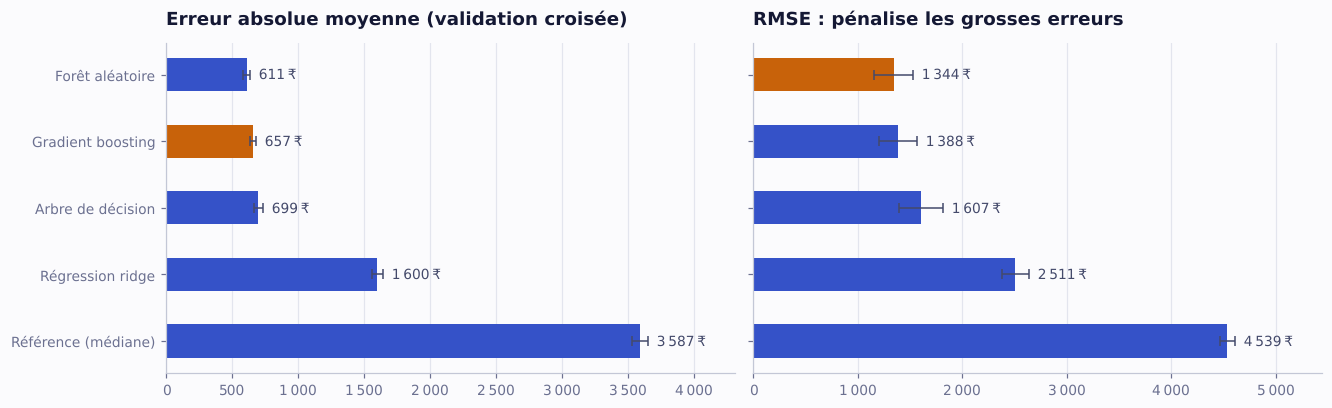

In [13]:
fig, axes = plotting.new_figure(12, 3.6, ncols=2)
plotting.model_bars(cv_table, axes[0], "MAE", highlight="Gradient boosting")
axes[0].set_title("Erreur absolue moyenne (validation croisée)")
plotting.model_bars(cv_table, axes[1], "RMSE", highlight="Gradient boosting")
axes[1].set_title("RMSE : pénalise les grosses erreurs")
axes[1].set_yticklabels([])
plotting.save(fig, "comparaison_modeles")
plotting.plt.show()

**Lecture.**

- La **référence** se trompe en moyenne de 3 587 ₹. Tout modèle utile doit faire nettement mieux.
- La **régression ridge** divise cette erreur par deux (1 600 ₹, R² = 0,69). Elle reste trop rigide : l'effet d'une escale dépend de la compagnie, de la ligne et de la date, des interactions qu'un modèle linéaire ne capte pas.
- Les **arbres** captent ces interactions : 699 ₹ pour un arbre seul, 611 ₹ pour la forêt aléatoire, qui obtient la meilleure MAE.
- Le **gradient boosting** a la meilleure RMSE (1 344 ₹) et le meilleur R² (0,909) : il fait moins de grosses erreurs.

Forêt et gradient boosting sont au coude à coude. On retient le **gradient boosting**, pour deux raisons : sa RMSE est la plus basse, et il reste assez compact (400 arbres de profondeur 6) pour tourner dans un navigateur, ce qui permet le simulateur du site. C'est lui que l'on règle.

## 7. Réglage du gradient boosting

> **Question.** Quels hyperparamètres retenir ?

Une recherche aléatoire teste 12 combinaisons par validation croisée sur l'entraînement uniquement : nombre d'arbres, profondeur, taux d'apprentissage, effectif minimal par feuille et sous-échantillonnage. L'espace est borné à 400 arbres de profondeur 6 au plus, pour que le modèle reste exportable.

In [14]:
search = modeling.tune_gradient_boosting(x_train, y_train)
display(modeling.search_results(search).head(6).style.format(
    {"MAE": "{:,.0f} ₹", "RMSE": "{:,.0f} ₹", "MAPE": "{:.1%}", "R2": "{:.3f}"}
))
print("Meilleure combinaison :", {k.split("__")[-1]: v for k, v in search.best_params_.items()})

,subsample,n_estimators,min_samples_leaf,max_depth,learning_rate,MAE,RMSE,MAPE,R2
0,1.000000,400,5,6,0.080000,662 ₹,"1,337 ₹",7.2%,0.910
1,0.700000,300,5,6,0.150000,668 ₹,"1,349 ₹",7.2%,0.908
2,0.800000,300,5,6,0.100000,667 ₹,"1,353 ₹",7.2%,0.907
3,0.800000,400,5,5,0.100000,692 ₹,"1,357 ₹",7.5%,0.907
4,1.000000,300,2,6,0.080000,680 ₹,"1,364 ₹",7.4%,0.906
5,0.700000,400,5,5,0.150000,688 ₹,"1,381 ₹",7.4%,0.903


Meilleure combinaison : {'subsample': 1.0, 'n_estimators': 400, 'min_samples_leaf': 5, 'max_depth': 6, 'learning_rate': 0.08}


**Lecture.** La meilleure combinaison (400 arbres de profondeur 6, taux d'apprentissage 0,08, au moins 5 vols par feuille, sans sous-échantillonnage) atteint une RMSE de 1 337 ₹ en validation croisée, contre 1 344 ₹ avant réglage. Le gain est faible : les réglages de départ étaient déjà proches de l'optimum, et le classement des modèles ne change pas.

## 8. Évaluation finale sur le jeu de test

> **Question.** Que vaut le modèle retenu sur des vols qu'il n'a jamais vus ?

Chaque modèle est réentraîné sur tout l'entraînement, puis mesuré **une seule fois** sur le jeu de test. Le choix du modèle a été fait avant cette étape ; les autres lignes du tableau ne servent qu'à situer le résultat.

In [15]:
finalists = {name: m for name, m in modeling.candidate_models().items() if name != "Gradient boosting"}
finalists["Gradient boosting (réglé)"] = search.best_estimator_
test_table, fitted = modeling.evaluate_on_test(finalists, x_train, y_train, x_test, y_test)
final = fitted["Gradient boosting (réglé)"]
y_pred = final.predict(x_test)

display(test_table.style.format({"MAE": "{:,.0f} ₹", "RMSE": "{:,.0f} ₹", "MAPE": "{:.1%}", "R2": "{:.3f}"}))
mae = test_table.loc["Gradient boosting (réglé)", "MAE"]
print(f"Erreur absolue moyenne du modèle retenu : {fr(mae, unit='₹')} ≈ {fr(inr_to_eur(mae), 2, '€')}")

,MAE,RMSE,MAPE,R2
modèle,,,,
Référence (médiane),"3,574 ₹","4,443 ₹",49.4%,-0.026
Régression ridge,"1,554 ₹","2,355 ₹",17.8%,0.712
Arbre de décision,651 ₹,"1,401 ₹",7.6%,0.898
Forêt aléatoire,557 ₹,"1,137 ₹",6.3%,0.933
Gradient boosting (réglé),615 ₹,"1,093 ₹",6.9%,0.938


Erreur absolue moyenne du modèle retenu : 615 ₹ ≈ 7,80 €


Intervalle à 80 % (hors-pli, entraînement) : prix réel entre −10,6 % et +11,5 % du prix prédit
Couverture observée sur le test : 82,4 %


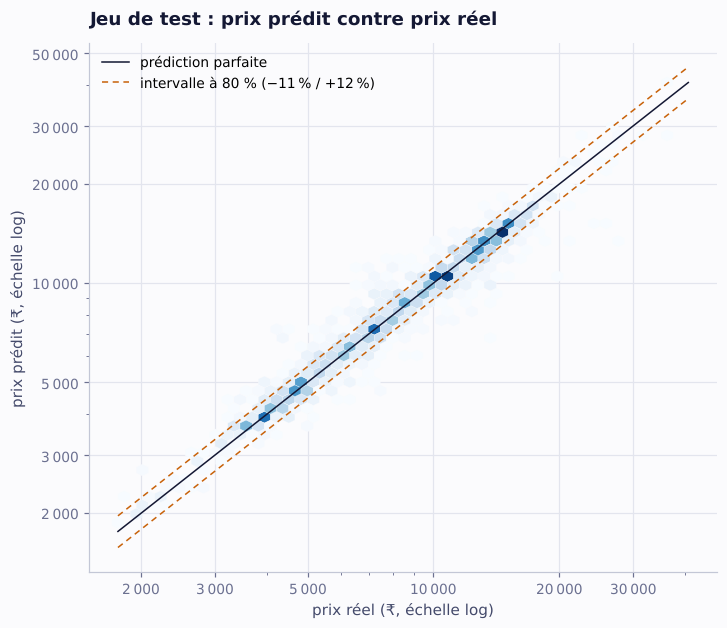

In [16]:
low, high = modeling.ratio_interval(search.best_estimator_, x_train, y_train)
inside = ((y_test / y_pred >= low) & (y_test / y_pred <= high)).mean()
print(f"Intervalle à 80 % (hors-pli, entraînement) : prix réel entre {fr_pct(low - 1, signed=True)} et {fr_pct(high - 1, signed=True)} du prix prédit")
print(f"Couverture observée sur le test : {fr_pct(inside)}")

fig, ax = plotting.new_figure(6.5, 5.6)
plotting.predicted_vs_actual(y_test.to_numpy(), y_pred, ax, interval=(low, high))
ax.set_title("Jeu de test : prix prédit contre prix réel")
plotting.save(fig, "predit_vs_reel")
plotting.plt.show()

In [17]:
print(f"Gradient boosting : {fr(modeling.node_count(final))} nœuds")
print(f"Forêt aléatoire   : {fr(modeling.node_count(fitted['Forêt aléatoire']))} nœuds")

Gradient boosting : 35 372 nœuds
Forêt aléatoire   : 1 998 916 nœuds


**Lecture.** Sur les 2 091 vols du test, le modèle retenu se trompe en moyenne de **615 ₹ (≈ 7,80 €)**, soit **6,9 %** du prix, avec un **R² de 0,938**. Ce score est un peu meilleur qu'en validation croisée (R² = 0,910) : le jeu de test contient un peu moins de cas extrêmes. Le chiffre de validation croisée reste l'estimation prudente.

La forêt aléatoire garde une MAE plus faible (557 ₹) mais une RMSE plus élevée (1 137 ₹ contre 1 093 ₹) : elle se trompe plus souvent de beaucoup. Elle est aussi 56 fois plus volumineuse (2 millions de nœuds contre 35 000), ce qui confirme le choix du gradient boosting pour le simulateur.

Pour 80 % des vols, le prix réel se situe entre −11 % et +12 % du prix prédit. Cet intervalle est estimé sur les prédictions hors-pli de l'entraînement, et sa couverture sur le test (82 %) le confirme. La plupart des points suivent la diagonale. Les écarts restants concernent surtout des billets chers, au-delà de 15 000 ₹.

## 9. Interprétation

> **Question.** Sur quoi le modèle s'appuie-t-il, et où se trompe-t-il ?

L'importance par permutation mesure de combien l'erreur du modèle augmente quand on mélange au hasard les valeurs d'une variable sur le jeu de test. Elle se lit en roupies et ne dépend pas de la structure interne du modèle.

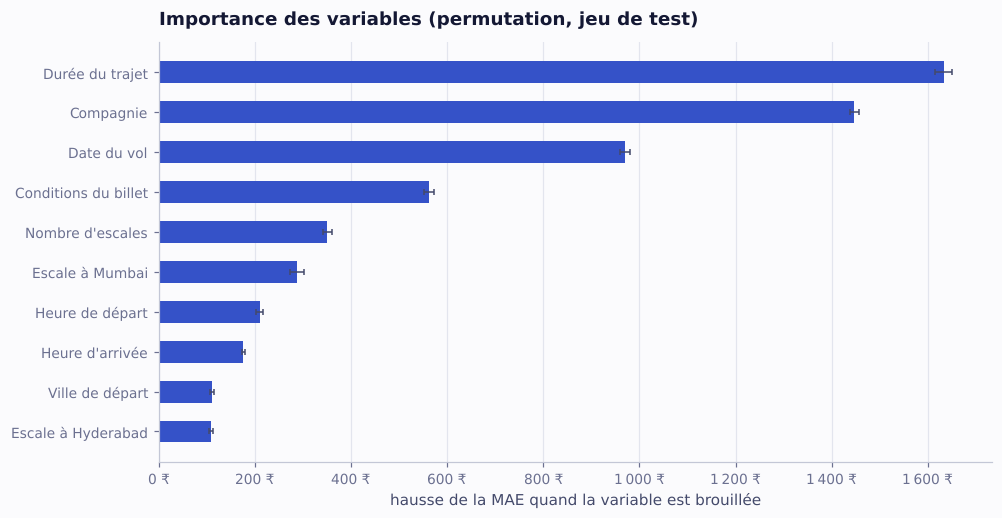

In [18]:
importances = modeling.feature_importances(final, x_test, y_test)
fig, ax = plotting.new_figure(9, 4.6)
plotting.importance_bars(importances, ax, FEATURE_LABELS)
ax.set_title("Importance des variables (permutation, jeu de test)")
plotting.plt.show()

**Lecture.** La **durée du trajet** est la variable la plus utile : brouillée, elle fait grimper l'erreur moyenne de 1 633 ₹. Viennent ensuite la **compagnie** (+1 447 ₹), la **date du vol** (+969 ₹, l'effet « réservation tardive » de début mars), les **conditions du billet** (+563 ₹) et le **nombre d'escales** (+351 ₹). L'escale à Mumbai, plaque tournante de Jet Airways, ressort parmi les aéroports. Les horaires jouent un rôle secondaire.

In [19]:
test_flights = flights.loc[x_test.index]
by_airline = modeling.errors_by(test_flights["airline"], y_test, y_pred)
price_band = pd.qcut(y_test, 4, labels=["25 % les moins chers", "2e quart", "3e quart", "25 % les plus chers"])
by_band = modeling.errors_by(price_band, y_test, y_pred)
fmt = {"MAE": "{:,.0f} ₹", "biais": "{:+,.0f} ₹", "MAPE": "{:.1%}"}
display(by_airline.style.format(fmt), by_band.style.format(fmt))

,vols,MAE,biais,MAPE
groupe,,,,
SpiceJet,156,230 ₹,-12 ₹,5.0%
IndiGo,409,362 ₹,-34 ₹,5.9%
Air Asia,59,382 ₹,+94 ₹,7.9%
Vistara,78,418 ₹,-59 ₹,5.1%
GoAir,41,573 ₹,+249 ₹,10.6%
Jet Airways,776,579 ₹,-20 ₹,5.4%
Air India,340,858 ₹,-112 ₹,8.3%
Multiple carriers,232,"1,219 ₹",-69 ₹,12.3%


,vols,MAE,biais,MAPE
groupe,,,,
25 % les moins chers,523,265 ₹,+133 ₹,6.4%
2e quart,523,570 ₹,+195 ₹,8.4%
3e quart,525,638 ₹,+22 ₹,6.2%
25 % les plus chers,520,990 ₹,-494 ₹,6.3%


**Lecture.** En valeur relative, l'erreur est homogène d'une compagnie à l'autre (de 4 à 8 % environ). En roupies, elle est plus forte pour les compagnies chères, Jet Airways et les vols « multi-compagnies ». Par tranche de prix, le modèle surestime légèrement les billets les moins chers et sous-estime les plus chers : c'est le rétrécissement vers la moyenne typique d'un modèle de régression.

## 10. Conclusion et limites

**Ce que l'on retient**

- Avec seulement ce qu'un voyageur sait en cherchant un vol, un gradient boosting prédit le prix d'un billet économique à **615 ₹ près en moyenne (≈ 7,80 €, 6,9 %)**, avec **R² = 0,94** sur des vols jamais vus.
- Le prix dépend d'abord de la **durée** et des **escales**, de la **compagnie** et de la **date du vol**, cette dernière servant de substitut au délai de réservation.
- Les modèles d'ensemble (forêt, boosting) l'emportent nettement sur la régression linéaire, car l'effet de chaque facteur dépend des autres.

**Limites**

- **Période et lignes limitées.** Les vols vont de mars à juin 2019 et couvrent cinq liaisons. Le modèle ne dit rien d'autres lignes ni d'autres années ; Jet Airways a d'ailleurs cessé ses vols en avril 2019.
- **Pas de date d'achat.** Le délai de réservation, sans doute le premier déterminant d'un prix de billet, n'est connu qu'indirectement.
- **Bruit irréductible.** 201 combinaisons identiques ont plusieurs prix : une partie de l'erreur restante ne peut pas être expliquée avec ces données.
- **Classe affaires exclue** (7 billets).
- **Conversion en euros** au taux moyen 2019, à titre indicatif.

**Pistes.** Relever les prix à plusieurs dates d'achat pour mesurer l'effet du délai de réservation, couvrir davantage de lignes et de mois, et estimer des intervalles de prédiction conditionnels (régression quantile) plutôt qu'un intervalle global.

### Note sur la version d'origine

Cette version reprend le projet initial (`MODELE.ipynb`) et corrige plusieurs problèmes de méthode :

- la régression linéaire était réentraînée sur le jeu de test avant d'être évaluée sur ce même jeu ;
- la sélection de variables (ExtraTrees + `SelectFromModel`) était apprise sur toutes les données, test compris : c'est une fuite d'information ;
- les hyperparamètres (nombre d'arbres, de variables) étaient choisis d'après le score sur le test ;
- certains graphiques affichaient de mauvaises variables (`predictions` à la place de `Y_predictions`, bornes d'axes de la forêt) ;
- dans la boucle sur `max_features`, les scores de la boucle précédente étaient réutilisés ;
- l'arbre « réglé » utilisait d'autres paramètres que les meilleurs trouvés ;
- les doublons exacts n'étaient pas retirés, et les billets à plus de 300 € l'étaient sans justification.